# 03 · Calibrating differential abundance against a known truth

**Question:** Which statistical test, cutoff and missing-value strategy give a list of "changed proteins" that can be trusted, and how many replicates are needed to find real changes?

**Why this is hard to answer on ordinary data:** in a real experiment the truth is unknown, so a method that reports more hits might be more powerful or simply more wrong. You can only grade a method where the answer is known.

**How the truth is built in.** Notebook 02 established that the 91 plasma wells of PXD018874 are technical replicates of commercial pooled plasma (a few donor-variable proteins, such as immunoglobulins, differ more between wells than technical noise alone would explain; section 4b shows why that matters). So:
1. **Two random groups of plasma wells differ by nothing.** Every "hit" between them is a false positive. That measures false positive rates directly.
2. **Known changes are spiked in.** A random 20% of proteins are shifted by known log2 fold changes (±0.58, ±1, ±2; that is 1.5-, 2- and 4-fold) in one group.
   * The shift is applied at **precursor level**, so peptides pushed below the detection limit disappear, as in a real experiment.
   * The proteins are then **rolled up with the same MaxLFQ** as Notebook 02.
3. **Repetition gives stable estimates.** This is repeated 50 times per scenario, at 3, 5 and 10 replicates per group and at three noise levels, so FDR and power are estimated with known uncertainty.

**Inputs:** Notebook 02 outputs in `data/processed/` (normalized precursors, sample table).
**Outputs:** the cached simulation results, and a recommended analysis (`stats.differential`) that later notebooks, including a degrader screen, call directly.

*A note on data choice.* The original plan used the hybrid-proteome benchmark (PXD028735). The only pre-searched DIA-NN report available turned out to be a 30-protein demo excerpt, too small to calibrate anything. The semi-synthetic approach used here is a recognised alternative. Its one blind spot (ratio compression from co-eluting peptides in real mixtures) is discussed in §8.

| § | Question |
|---|---|
| 1 | Do the test implementations work? (validated on synthetic data first) |
| 2 | Does variance depend on intensity in this data, and does it matter? |
| 3 | Under no true differences, are p-values honest? |
| 4 | With known changes, which test controls false discoveries and finds the most true ones? |
| 4b | Stress test: does that hold when a small study can only normalize its own runs? |
| 5 | Are fold-change cutoffs or unadjusted p-values acceptable shortcuts? |
| 6 | Should missing values be imputed, and how should "on/off" proteins be handled? |
| 7 | Are fold changes estimated without bias? |
| 8 | Recommended settings, and how many replicates a study needs |
| 9 | Applying it to real data, and how to reuse it for a new (e.g. degrader) dataset |
| 10 | Summary and limitations |

> **Results at a glance** (details in the sections listed)
>
> | Finding | Decision | § |
> |---|---|---|
> | Our moderated t-test, written from the equations, reproduces limma (the reference implementation) to ~1e-10, including the intensity trend | Implementation verified, also as an automated test | 1 |
> | Low-abundance proteins are ~4× noisier (ρ = −0.69) | Use an intensity-dependent variance prior | 2 |
> | 3 vs 3 at CV ~18%: every test keeps FDR near 5%, but the moderated t (trend) finds 70% of true changes vs 28% for Welch | **Moderated t (trend)** | 3, 4 |
> | Stress test: when each small experiment normalizes its own runs and many proteins change unevenly, normalization shifts every protein ~0.03 log2, and FDR reaches 34–42% in precise data. Cause: imbalance of the true changes, not dropout (tested) | **q < 0.05 plus \|log2FC\| ≥ 0.58** (FDR ≤ 4.2%); treat q < 0.05 lists as ~5–10% FDR in real studies | 4b |
> | Fold change alone lets up to 33% false hits through; unadjusted p 16–26% | Multiple-testing correction is not optional | 5 |
> | Imputation never helps testing; "absent from one group" is a true change only ~half the time | No imputation; on/off proteins in a separate tier (~5% false) | 6 |
> | At CV ~18%, 3 replicates find ~80% of 2-fold but ~⅓ of 1.5-fold changes | Design guidance for the degrader dataset | 8 |

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Find the repository root whether the notebook runs from /notebooks or from the root
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src import stats, impute, simulate, benchmark, qc, normalize, plotting
from src.plotting import INK_MUTED

PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "figures"
plotting.set_style()
pd.set_option("display.precision", 3)

# Colours for the three tests compared throughout (fixed for every figure)
TEST_COLORS = {"welch": "#8c8b85", "moderated": "#2a78d6", "moderated (trend)": "#eb6834"}
TESTS = list(TEST_COLORS)

# Simulations take about 20 minutes; results are cached so re-running the notebook is fast.
# Set RERUN = False to regenerate them from scratch.
RERUN = False

inputs = [PROCESSED / "02_precursors_normalized.parquet", PROCESSED / "02_sample_table.csv",
          PROCESSED / "01_precursors_filtered.parquet"]
missing = [p.name for p in inputs if not p.exists()]
if missing:
    raise FileNotFoundError(f"Run Notebooks 01 and 02 first; missing {missing} in data/processed/")

In [2]:
# Normalized precursors (Notebook 02) as a precursor x run matrix, and each precursor's protein group
meta = pd.read_csv(PROCESSED / "02_sample_table.csv", index_col=0)
precursors = (pd.read_parquet(PROCESSED / "02_precursors_normalized.parquet")
                .pivot(index="Precursor.Id", columns="run", values="log2_normalized"))
annot = pd.read_parquet(PROCESSED / "01_precursors_filtered.parquet").drop_duplicates("Precursor.Id")
protein_of = annot.set_index("Precursor.Id")["Protein.Group"]
gene_of = annot.drop_duplicates("Protein.Group").set_index("Protein.Group")["Genes"]

# The pool of technical replicates that simulations draw from
pool = meta.index[meta["sample_type"] == "Plasma"]

# Raw (un-normalized) precursor quantities and retention times, for the stress test in section 4b,
# where each simulated experiment normalizes only its own runs
long = pd.read_parquet(PROCESSED / "01_precursors_filtered.parquet",
                       columns=["Precursor.Id", "run", "Precursor.Quantity", "RT"])
long = long[long["run"].isin(meta.index)]
raw = np.log2(long.pivot(index="Precursor.Id", columns="run", values="Precursor.Quantity"))
rt = long.groupby("Precursor.Id")["RT"].median()
plates = meta.loc[pool, "plate"]          # a small study is acquired in one batch: one plate
print(f"{precursors.shape[0]:,} precursors | simulation pool: {len(pool)} plasma wells (technical replicates)")

3,674 precursors | simulation pool: 91 plasma wells (technical replicates)


## 1. Validate the test implementations on synthetic data

Three tests are compared (all in `src/stats.py`):

| Test | Idea | Known issue |
|---|---|---|
| **Welch's t** | Each protein on its own; unequal group variances allowed | With 3 replicates a variance is estimated from very few values, so some come out tiny by chance and produce false "hits", while the test compensates by being conservative |
| **Moderated t** (limma-style empirical Bayes) | Each protein's variance is shrunk towards a typical value learned from *all* proteins | Assumes one typical variance for every protein |
| **Moderated t, intensity trend** (limma `trend=TRUE`) | The typical variance follows average intensity | Needs enough proteins to fit the trend |

Before trusting any of them on real data, check them on synthetic data where the truth is known exactly:
* the prior must be recovered
* null p-values must be uniform
* the trend version must fix intensity-dependent noise

In [3]:
# Test 1: 5,000 features with NO true differences; true variances drawn from a known prior (d0 = 4, s0^2 = 0.05)
rng = np.random.default_rng(0)
n_feat, n = 5000, 3
true_var = 4 * 0.05 / rng.chisquare(4, n_feat)                 # scaled inverse chi-square
sim = pd.DataFrame(rng.normal(0, np.sqrt(true_var)[:, None], (n_feat, 2 * n)),
                   columns=[f"r{i}" for i in range(2 * n)])
a, b = sim.columns[:n], sim.columns[n:]

mod, (d0, s0_sq) = stats.moderated_t(sim, a, b, return_prior=True)
wel = stats.welch_t(sim, a, b)
from scipy.stats import kstest
print(f"Prior recovered: d0 = {d0:.2f} (true 4), s0^2 = {s0_sq:.4f} (true 0.05)")
for name, res in [("Welch", wel), ("moderated", mod)]:
    print(f"{name:>9}: p < 0.05 in {np.mean(res['p'] < 0.05):.3f} of null features (should be 0.05); "
          f"uniformity test p = {kstest(res['p'], 'uniform').pvalue:.2g}")

Prior recovered: d0 = 4.01 (true 4), s0^2 = 0.0498 (true 0.05)
    Welch: p < 0.05 in 0.036 of null features (should be 0.05); uniformity test p = 2.6e-06
moderated: p < 0.05 in 0.051 of null features (should be 0.05); uniformity test p = 0.27


In [4]:
# Test 2: noise that grows as intensity falls (as in real proteomics), 10% of features truly changed
rng = np.random.default_rng(3)
intensity = rng.uniform(8, 14, 3000)
true_sd = 0.03 * np.exp(-0.35 * (intensity - 14)) * np.exp(rng.normal(0, 0.3, 3000))
x = intensity[:, None] + rng.normal(0, 1, (3000, 6)) * true_sd[:, None]
changed = rng.choice(3000, 300, replace=False)
x[changed, 3:] += (rng.choice([-1, 1], 300) * 0.5)[:, None]
sim2 = pd.DataFrame(x, columns=[f"r{i}" for i in range(6)])
null_idx = np.setdiff1d(np.arange(3000), changed)
low = intensity[null_idx] < np.quantile(intensity, 0.25)

rows = []
for test in TESTS:
    res = stats.TESTS[test](sim2, sim2.columns[:3], sim2.columns[3:])
    called = (res["q"] < 0.05).to_numpy()
    p_null = res["p"].to_numpy()[null_idx]
    rows.append({"test": test,
                 "null p<0.05, low-intensity quarter": np.mean(p_null[low] < 0.05),
                 "null p<0.05, rest": np.mean(p_null[~low] < 0.05),
                 "empirical FDR (q<0.05)": (called.sum() - called[changed].sum()) / max(called.sum(), 1),
                 "power": called[changed].mean()})
pd.DataFrame(rows).set_index("test").round(3)

,"null p<0.05, low-intensity quarter","null p<0.05, rest",empirical FDR (q<0.05),power
test,,,,
welch,0.041,0.044,0.021,0.463
moderated,0.102,0.041,0.060,0.790
moderated (trend),0.053,0.052,0.049,0.843


**Result**
* **The moderated t recovers the prior almost exactly**, and its null p-values are uniform.
* **Welch's test is conservative at n = 3:** about 3.5% instead of 5% false positives, and non-uniform p-values. It wastes power rather than inventing hits.
* **When noise grows at low intensity, the plain moderated t produces false positives among low-intensity proteins** (about 10% instead of 5%), because it shrinks their variances towards a typical value that is too small for them.
* **The intensity-trend version restores 5% in every intensity range** and gains power.
* So the implementations behave as theory predicts. Next: does real data have that intensity dependence?

In [5]:
# Test 3: agreement with limma, the reference implementation of the moderated t-test (Smyth 2004).
# Our code was written from the paper's equations, not ported from limma, so agreement is an independent check
# of every step: the variance prior, the shrinkage, the degrees of freedom and the intensity trend.
# The reference values were produced by limma (via inmoose, a Python port) on a fixed synthetic dataset
# with intensity-dependent noise and 8% missing values; tests/data/make_limma_reference.py regenerates them.
x_ref = pd.read_csv(ROOT / "tests" / "data" / "limma_input.csv", index_col=0)
limma_ref = pd.read_csv(ROOT / "tests" / "data" / "limma_reference.csv", index_col=0)
a_ref = [c for c in x_ref.columns if c.startswith("A")]
b_ref = [c for c in x_ref.columns if c.startswith("B")]
for tag, trend in [("plain", False), ("trend", True)]:
    ours, (d0_ours, _) = stats.moderated_t(x_ref, a_ref, b_ref, return_prior=True, trend=trend)
    print(f"{tag:>5}: prior df ours {d0_ours:.6f} vs limma {limma_ref[f'df_prior_{tag}'].iloc[0]:.6f} | "
          f"max |t difference| = {np.max(np.abs(ours['t'] - limma_ref[f't_{tag}'])):.1e} "
          f"over {len(x_ref)} proteins")

plain: prior df ours 2.029875 vs limma 2.029875 | max |t difference| = 4.9e-11 over 299 proteins
trend: prior df ours 5.959251 vs limma 5.959251 | max |t difference| = 4.9e-11 over 299 proteins


**Both versions reproduce limma to about 10 decimal places.** One detail mattered: limma fits the intensity trend with a natural cubic spline (4 degrees of freedom). An earlier version of this code used a LOWESS curve, which gave t-statistics up to about 3 units different on the plasma data. The spline is now used, for two reasons:
* with about 150 proteins, a low-flexibility global curve is less likely to chase noise at the intensity extremes than a local smoother
* matching the reference implementation exactly makes the code verifiable by anyone

The same comparison runs as an automated test (`tests/test_limma_crosscheck.py`) on every push.

## 2. Does variance depend on intensity in this data?

Spearman rho (SD vs intensity) = -0.69; median SD by intensity quarter: {'lowest': 0.109, '2nd': 0.054, '3rd': 0.045, 'highest': 0.027}


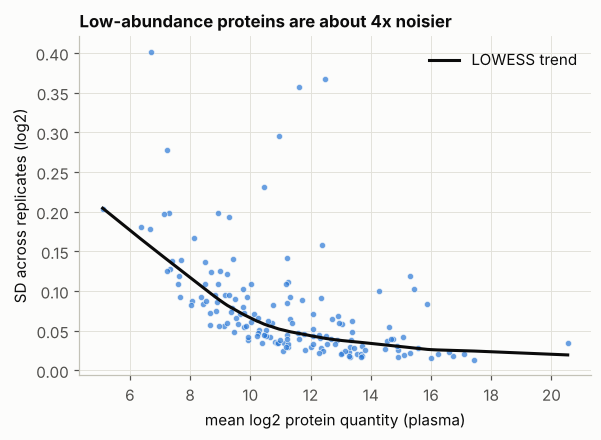

In [6]:
# Protein-level SD across the plasma replicates vs mean intensity (Notebook 02 protein values)
proteins_all = pd.read_parquet(PROCESSED / "02_proteins_maxlfq.parquet")
mv = pd.DataFrame({"mean": proteins_all[pool].mean(axis=1), "sd": proteins_all[pool].std(axis=1)}).dropna()
from scipy.stats import spearmanr
rho = spearmanr(mv["mean"], mv["sd"])[0]
quart = mv.groupby(pd.qcut(mv["mean"], 4, labels=["lowest", "2nd", "3rd", "highest"]))["sd"].median()
print(f"Spearman rho (SD vs intensity) = {rho:.2f}; median SD by intensity quarter:", quart.round(3).to_dict())

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(mv["mean"], mv["sd"], s=16, color="#2a78d6", alpha=0.7, edgecolor=plotting.SURFACE, linewidth=0.5)
x_fit, y_fit = qc.lowess_trend(mv["mean"], mv["sd"], frac=0.6)
ax.plot(x_fit, y_fit, color="#0b0b0b", lw=2, label="LOWESS trend")
ax.set_xlabel("mean log2 protein quantity (plasma)")
ax.set_ylabel("SD across replicates (log2)")
ax.set_title("Low-abundance proteins are about 4x noisier")
ax.legend()
plotting.save_figure(fig, "03_mean_variance", FIGURES)
plt.show()

**Yes.** SD falls about 4-fold from the least to the most abundant proteins (ρ ≈ −0.69), the situation in which the plain moderated t mis-calibrates (§1). The intensity-trend version is therefore the principled choice. The simulations below test whether that matters in practice.

## 3. Under no true differences, are p-values honest?

**Setup:**
* Random groups of plasma wells, with no spike-ins.
* Three noise levels:
  * **technical only** (as measured)
  * **+ biological SD 0.25 log2** (CV about 18%, typical for replicate cell cultures)
  * **+ SD 0.5 log2** (CV about 35%, a noisy experiment)

**Why add noise at all?** Technical replicates are cleaner than any real biological study, so conclusions must hold beyond them. The added noise is applied per protein and shared by its precursors (as biological variation would be), with protein-to-protein differences in variability (`simulate.add_biological_noise`).

**Expectation:** an honest test gives p < 0.05 for 5% of proteins.

In [7]:
grid = dict(n_per_group=[3, 5, 10], noise_sd=[0.0, 0.25, 0.5])
null_file = PROCESSED / "03_sim_null.parquet"
if RERUN or not null_file.exists():
    # fraction_changed = 0: nothing is spiked, so every hit is false
    null = benchmark.run_grid(precursors, protein_of, pool, n_sims=50, seed=1, tests=TESTS,
                              fraction_changed=[0.0], **grid)
    null.to_parquet(null_file)
null = pd.read_parquet(null_file)

tested = null[null["p"].notna()]
calib = tested.groupby(["n_per_group", "noise_sd", "test"])["p"].apply(lambda p: (p < 0.05).mean()).unstack()
calib.round(3)

test                  moderated  moderated (trend)  welch
n_per_group noise_sd                                     
3.0         0.00          0.047              0.046  0.031
            0.25          0.053              0.054  0.035
            0.50          0.055              0.055  0.033
5.0         0.00          0.049              0.048  0.036
            0.25          0.054              0.053  0.046
            0.50          0.048              0.049  0.041
10.0        0.00          0.044              0.046  0.044
            0.25          0.055              0.055  0.054
            0.50          0.051              0.051  0.051

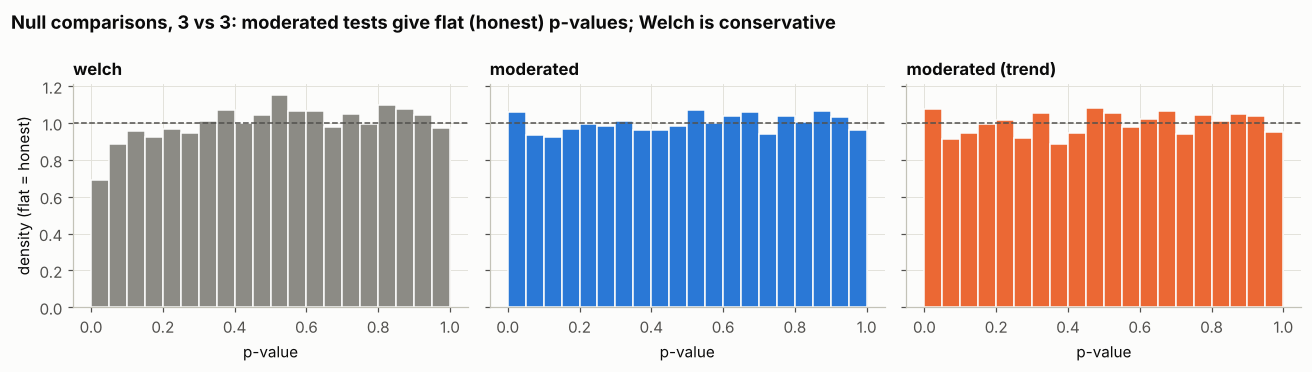

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
sub = tested[(tested["n_per_group"] == 3) & (tested["noise_sd"] == 0.25)]
bins = np.linspace(0, 1, 21)
for ax, test in zip(axes, TESTS):
    ax.hist(sub.loc[sub["test"] == test, "p"], bins=bins, color=TEST_COLORS[test], edgecolor=plotting.SURFACE,
            density=True)
    ax.axhline(1, color=INK_MUTED, lw=1, ls="--")
    ax.set_title(test)
    ax.set_xlabel("p-value")
axes[0].set_ylabel("density (flat = honest)")
fig.suptitle("Null comparisons, 3 vs 3: moderated tests give flat (honest) p-values; Welch is conservative",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plotting.save_figure(fig, "03_null_pvalues", FIGURES)
plt.show()

**Interpretation**
* **Both moderated tests are honest in every scenario:** 4.4–5.5% of null proteins have p < 0.05, against 5% expected. Their p-value histograms are flat.
* **Welch's test is conservative at small n** (about 3.1–3.6% at n = 3) and only becomes exact at n = 10. Its p-value histogram is depleted near 0.
* A conservative test does not create false positives; it **misses real changes**. §4 measures how many.

## 4. With known changes: false discoveries and power

**Setup:**
* In each simulated experiment, 20% of quantifiable proteins are shifted in group B by a log2 fold change drawn from {−2, −1, −0.58, +0.58, +1, +2}.
* A call is **q < 0.05** after Benjamini–Hochberg.

**Scoring** (`benchmark.score`), pooled over 50 simulations per scenario:
* **Empirical FDR** = false calls / all calls. A changed protein called in the *wrong direction* counts as false.
* **Power** = correctly called changes / all true changes.

In [9]:
spike_file = PROCESSED / "03_sim_spike.parquet"
if RERUN or not spike_file.exists():
    spike = benchmark.run_grid(precursors, protein_of, pool, n_sims=50, seed=2, tests=TESTS, **grid)
    spike.to_parquet(spike_file)
spike = pd.read_parquet(spike_file)

scores = benchmark.score(spike).reset_index()
display(scores.pivot_table(index=["n_per_group", "noise_sd"], columns="test",
                           values=["empirical FDR", "power"]).round(3))

empirical FDR                              power  \
test                     moderated moderated (trend)  welch moderated   
n_per_group noise_sd                                                    
3.0         0.00             0.061             0.048  0.023     0.986   
            0.25             0.049             0.053  0.005     0.698   
            0.50             0.053             0.060  0.015     0.251   
5.0         0.00             0.039             0.035  0.032     0.991   
            0.25             0.045             0.047  0.033     0.837   
            0.50             0.037             0.037  0.023     0.498   
10.0        0.00             0.049             0.050  0.045     0.999   
            0.25             0.039             0.040  0.036     0.945   
            0.50             0.039             0.043  0.042     0.725   

                                               
test                 moderated (trend)  welch  
n_per_group noise_sd                           
3.0         0.00                 0.986  0.912  
            0.25                 0.699  0.282  
            0.50                 0.255  0.045  
5.0         0.00                 0.990  0.980  
            0.25                 0.835  0.758  
            0.50                 0.498  0.397  
10.0        0.00                 0.999  0.994  
            0.25                 0.945  0.921  
            0.50                 0.724  0.696

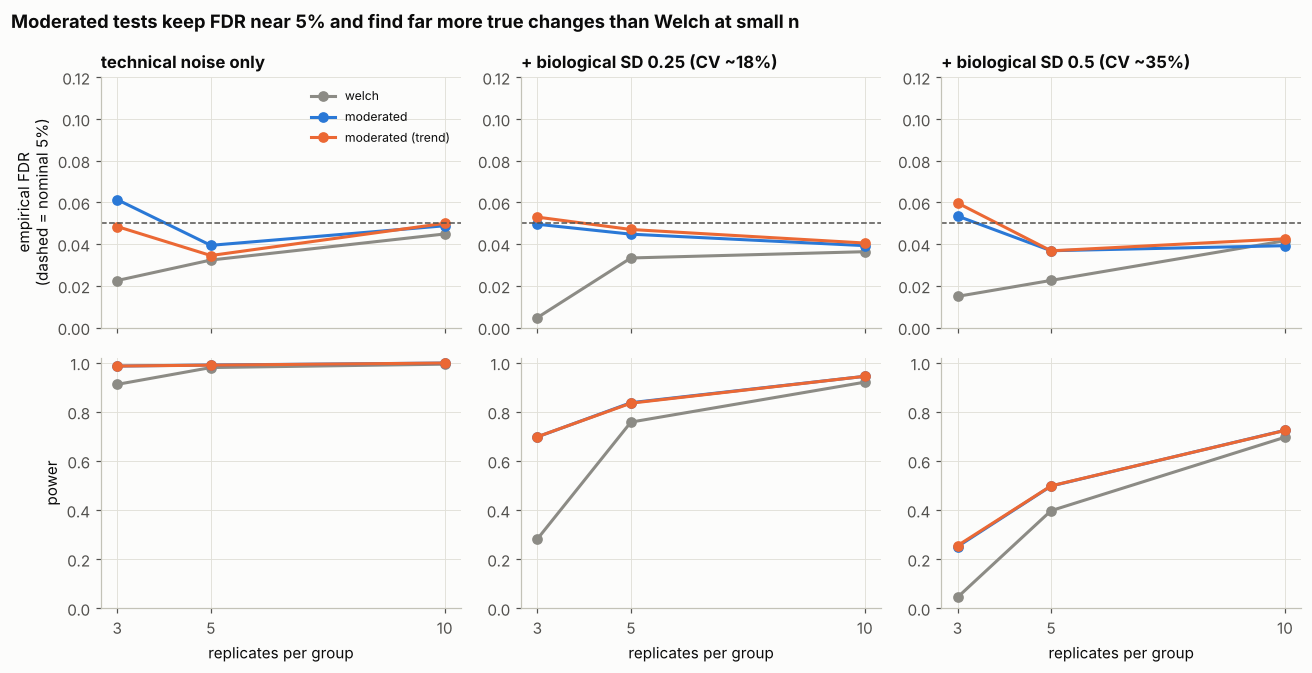

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6.2), sharex=True)
for j, noise in enumerate(grid["noise_sd"]):
    s = scores[scores["noise_sd"] == noise]
    for test in TESTS:
        t = s[s["test"] == test]
        axes[0, j].plot(t["n_per_group"], t["empirical FDR"], "-o", color=TEST_COLORS[test], label=test, markersize=6)
        axes[1, j].plot(t["n_per_group"], t["power"], "-o", color=TEST_COLORS[test], markersize=6)
    axes[0, j].axhline(0.05, color=INK_MUTED, lw=1, ls="--")
    axes[0, j].set_ylim(0, 0.12)
    axes[1, j].set_ylim(0, 1.02)
    label = {0.0: "technical noise only", 0.25: "+ biological SD 0.25 (CV ~18%)", 0.5: "+ biological SD 0.5 (CV ~35%)"}[noise]
    axes[0, j].set_title(label)
    axes[1, j].set_xlabel("replicates per group")
    axes[1, j].set_xticks(grid["n_per_group"])
axes[0, 0].set_ylabel("empirical FDR\n(dashed = nominal 5%)")
axes[1, 0].set_ylabel("power")
axes[0, 0].legend(loc="upper right", fontsize=8)
fig.suptitle("Moderated tests keep FDR near 5% and find far more true changes than Welch at small n",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plotting.save_figure(fig, "03_fdr_power", FIGURES)
plt.show()

**Interpretation**
* **All three tests keep the empirical FDR close to the nominal 5%** (moderated: 3.7–6.1%; trend: 3.5–6.0%; Welch: lower still, because it is conservative). With about 50 × 30 calls per scenario, ±1 point is within simulation error.
* **The difference is power, and it is large at small n:**
  * **3 vs 3, CV about 18%:** moderated tests find **70%** of true changes, Welch **28%**.
  * **3 vs 3, CV about 35%:** 26% vs **4.5%**. Welch is nearly blind.
  * **At n = 10 the gap almost closes**, because each protein then has enough replicates to estimate its own variance.
* **The trend version fixes the one mis-calibrated case.** With technical noise only, which is intensity-dependent (§2), FDR drops from 6.1% to 4.8%. Elsewhere it is equivalent within simulation error, because the added biological noise was simulated without an intensity trend.
* **Choice: moderated t with intensity trend.** It is honest in every scenario, as powerful as any alternative, and matches the measured noise structure.

## 4b. Stress test: normalizing inside each small experiment

**The concern.** Sections 3–4 drew runs from precursors that Notebook 02 had normalized using **all 205 runs**, including the sample-anchored drift correction (M7). A real 3 vs 3 study has 6 runs. It cannot fit a per-precursor drift curve, and its RT-dependent normalization has only those 6 runs to define "typical". In addition, the spike-ins were applied *after* normalization, so normalization never had to cope with the changes it is meant to preserve. Both flatter the results.

**The test.** Each simulated experiment now starts from **raw** precursor quantities and goes through what a small study can actually do:
1. simulated biology (added noise, spike-ins) on the raw values
2. RT-dependent LOWESS normalization (M3) fitted on **that experiment's runs only** (`benchmark.simulate_once(normalize=...)`)
3. MaxLFQ roll-up and the moderated t (trend), as before

| Scenario | Runs drawn from | Normalization |
|---|---|---|
| large-study normalization | any plasma well | Notebook 02 (all runs, M7) — sections 3–4 |
| in-experiment, one plate | one plate (as a small study acquired in one batch) | M3 on the experiment's own runs |
| in-experiment, any plate | any plasma well (worst case: drift and plate effects included) | M3 on the experiment's own runs |

Three amounts of change: none (null), 20% of proteins (as in section 4), and 5% (closer to a selective degrader). The LOWESS uses statsmodels' `delta` shortcut (1% of the RT range), which changes values by < 0.002 log2 and makes this about 20× faster (tested in `tests/test_normalize.py`).

**False discovery rates now carry 95% bootstrap intervals** (`benchmark.score(ci=0.95)`), resampling whole simulations. False calls are not independent: several co-varying proteins (e.g. immunoglobulins, whose levels differ between the donor pools behind these commercial plasma lots) tend to be called together in one unlucky experiment.

In [11]:
DELTA = 0.01 * float(rt.max() - rt.min())       # LOWESS speed-up: 1% of the RT range

def within(m):
    # What a small study can do: RT-dependent normalization fitted on its own runs only
    return normalize.rt_lowess_normalize(m, rt, frac=0.3, delta=DELTA)

def within_complete(m):
    # Same, but the curves are fitted only on precursors quantified in every run (a hypothesis tested below)
    return normalize.rt_lowess_normalize(m, rt, frac=0.3, delta=DELTA, complete_only=True)

SCENARIOS = {
    "large-study normalization": dict(log2_precursors=precursors),
    "in-experiment, one plate": dict(log2_precursors=raw, normalize=within, batches=plates),
    "in-experiment, any plate": dict(log2_precursors=raw, normalize=within),
    "in-experiment, one plate, complete-only fit": dict(log2_precursors=raw, normalize=within_complete,
                                                        batches=plates),
}
CHANGES = {"null": (0.0, 11, 50), "20% changed": (0.2, 12, 50), "5% changed": (0.05, 13, 100)}  # fraction, seed, sims
RUNS = [("in-experiment, one plate", "null"), ("in-experiment, any plate", "null"),
        ("in-experiment, one plate", "20% changed"), ("in-experiment, any plate", "20% changed"),
        ("in-experiment, one plate, complete-only fit", "20% changed"),
        ("large-study normalization", "5% changed"), ("in-experiment, one plate", "5% changed")]

smalln_file = PROCESSED / "03_sim_smalln.parquet"
if RERUN or not smalln_file.exists():       # about 17 minutes
    parts = []
    for scenario, change in RUNS:
        frac, seed, n_sims = CHANGES[change]
        res = benchmark.run_grid(protein_of=protein_of, pool_runs=pool, n_sims=n_sims, seed=seed,
                                 tests=("moderated (trend)",), n_per_group=[3, 5, 10], noise_sd=[0.0, 0.25],
                                 fraction_changed=[frac], **SCENARIOS[scenario])
        res["scenario"], res["change"] = scenario, change
        parts.append(res)
    pd.concat(parts, ignore_index=True).to_parquet(smalln_file)
smalln = pd.read_parquet(smalln_file)

# The large-study scenario at 0% and 20% change is exactly sections 3-4: reuse those simulations
trend_rows = lambda d: d[(d["test"] == "moderated (trend)") & d["noise_sd"].isin([0.0, 0.25])]
stress = pd.concat([smalln,
                    trend_rows(null).assign(scenario="large-study normalization", change="null"),
                    trend_rows(spike).assign(scenario="large-study normalization", change="20% changed")],
                   ignore_index=True)

# 1) Null: are p-values still honest when each experiment normalizes itself?
nul = stress[(stress["change"] == "null") & stress["p"].notna()]
display(nul.groupby(["scenario", "n_per_group", "noise_sd"])["p"].apply(lambda p: (p < 0.05).mean())
        .unstack("noise_sd").round(3).rename(columns=lambda c: f"null p<0.05, noise {c}"))

noise_sd                               null p<0.05, noise 0.0  \
scenario                  n_per_group                           
in-experiment, any plate  3.0                           0.056   
                          5.0                           0.041   
                          10.0                          0.051   
in-experiment, one plate  3.0                           0.064   
                          5.0                           0.063   
                          10.0                          0.049   
large-study normalization 3.0                           0.046   
                          5.0                           0.048   
                          10.0                          0.046   

noise_sd                               null p<0.05, noise 0.25  
scenario                  n_per_group                           
in-experiment, any plate  3.0                            0.056  
                          5.0                            0.048  
                          10.0                           0.048  
in-experiment, one plate  3.0                            0.056  
                          5.0                            0.053  
                          10.0                           0.051  
large-study normalization 3.0                            0.054  
                          5.0                            0.053  
                          10.0                           0.055

empirical FDR  \
noise_sd                                                                                       0.00   
rule                          scenario                                    n_per_group                 
q < 0.05                      in-experiment, any plate                    3.0                 0.083   
                                                                          5.0                 0.140   
                                                                          10.0                0.421   
                              in-experiment, one plate                    3.0                 0.109   
                                                                          5.0                 0.140   
                                                                          10.0                0.339   
                              in-experiment, one plate, complete-only fit 3.0                 0.126   
                                                                          5.0                 0.144   
                                                                          10.0                0.298   
                              large-study normalization                   3.0                 0.048   
                                                                          5.0                 0.035   
                                                                          10.0                0.050   
q < 0.05 and |log2FC| >= 0.58 in-experiment, any plate                    3.0                 0.003   
                                                                          5.0                 0.001   
                                                                          10.0                0.000   
                              in-experiment, one plate                    3.0                 0.006   
                                                                          5.0                 0.000   
                                                                          10.0                0.000   
                              in-experiment, one plate, complete-only fit 3.0                 0.006   
                                                                          5.0                 0.000   
                                                                          10.0                0.000   
                              large-study normalization                   3.0                 0.002   
                                                                          5.0                 0.002   
                                                                          10.0                0.000   

                                                                                              \
noise_sd                                                                                0.25   
rule                          scenario                                    n_per_group          
q < 0.05                      in-experiment, any plate                    3.0          0.048   
                                                                          5.0          0.061   
                                                                          10.0         0.097   
                              in-experiment, one plate                    3.0          0.038   
                                                                          5.0          0.064   
                                                                          10.0         0.072   
                              in-experiment, one plate, complete-only fit 3.0          0.039   
                                                                          5.0          0.066   
                                                                          10.0         0.078   
                              large-study normalization                   3.0          0.053   
                                                        

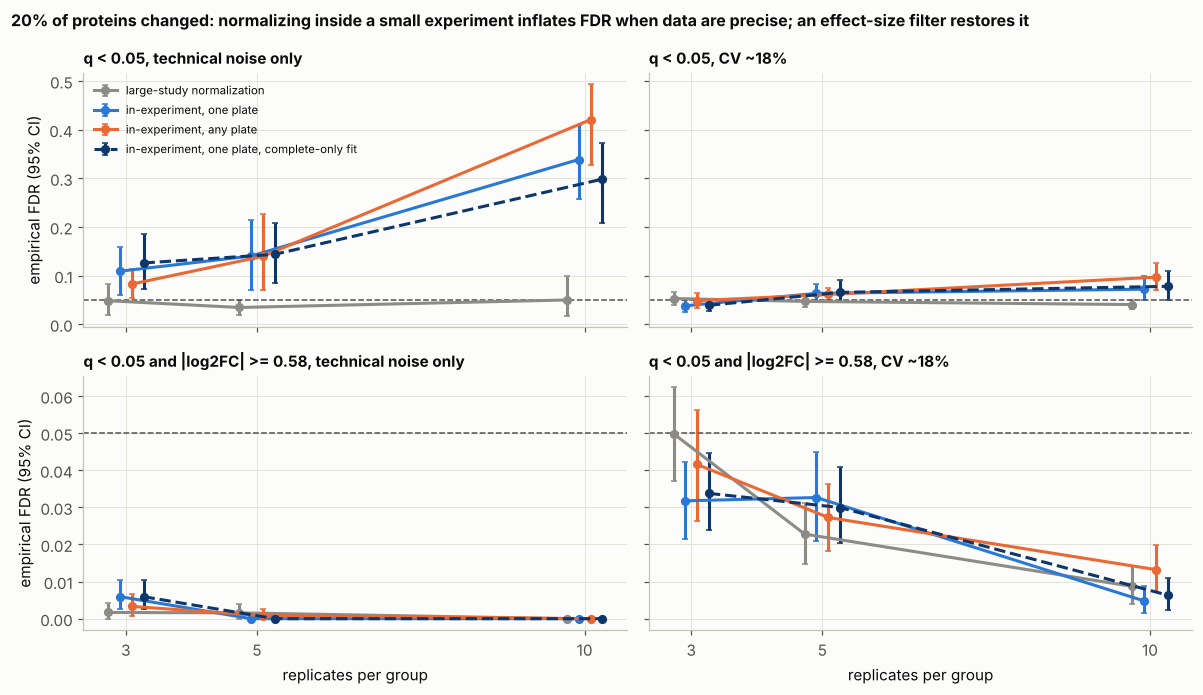

In [12]:
# 2) 20% of proteins changed: FDR (with 95% bootstrap interval) and power, with and without an effect-size filter
by = ("scenario", "n_per_group", "noise_sd")
s20 = stress[stress["change"] == "20% changed"]
fdr20 = {"q < 0.05": benchmark.score(s20, by=by, ci=0.95),
         "q < 0.05 and |log2FC| >= 0.58": benchmark.score(s20, by=by, ci=0.95, min_abs_fc=0.58)}
display(pd.concat(fdr20, names=["rule"])[["empirical FDR", "FDR low", "FDR high", "power"]]
        .unstack("noise_sd").round(3))

STRESS_COLORS = {"large-study normalization": "#8c8b85", "in-experiment, one plate": "#2a78d6",
                 "in-experiment, any plate": "#eb6834", "in-experiment, one plate, complete-only fit": "#0d366b"}
fig, axes = plt.subplots(2, 2, figsize=(11, 6.4), sharex=True, sharey="row")
for i, (rule, sc) in enumerate(fdr20.items()):
    sc = sc.reset_index()
    for j, noise in enumerate([0.0, 0.25]):
        ax = axes[i, j]
        for k, (scenario, color) in enumerate(STRESS_COLORS.items()):
            t = sc[(sc["scenario"] == scenario) & (sc["noise_sd"] == noise)]
            x = t["n_per_group"] + (k - 1.5) * 0.18                   # small offsets so intervals do not overlap
            ls = "--" if "complete" in scenario else "-"
            ax.errorbar(x, t["empirical FDR"], yerr=[t["empirical FDR"] - t["FDR low"], t["FDR high"] - t["empirical FDR"]],
                        fmt="o", ls=ls, color=color, ms=5, capsize=2, label=scenario)
        ax.axhline(0.05, color=INK_MUTED, lw=1, ls="--")
        ax.set_xticks([3, 5, 10])
        ax.set_title(f"{rule}, " + ("technical noise only" if noise == 0 else "CV ~18%"), fontsize=10)
    axes[i, 0].set_ylabel("empirical FDR (95% CI)")
for ax in axes[1]:
    ax.set_xlabel("replicates per group")
axes[0, 0].legend(fontsize=7.5, loc="upper left")
fig.suptitle("20% of proteins changed: normalizing inside a small experiment inflates FDR when data are precise; "
             "an effect-size filter restores it", x=0.01, ha="left", fontweight="bold", fontsize=10.5)
fig.tight_layout()
plotting.save_figure(fig, "03_stress_normalization", FIGURES)
plt.show()

SD of shift between experiments  \
noise_sd                                                                           0.00   
scenario                                    n_per_group                                   
in-experiment, any plate                    3.0                                   0.030   
                                            5.0                                   0.031   
                                            10.0                                  0.039   
in-experiment, one plate                    3.0                                   0.028   
                                            5.0                                   0.028   
                                            10.0                                  0.029   
in-experiment, one plate, complete-only fit 3.0                                   0.024   
                                            5.0                                   0.026   
                                            10.0                                  0.029   
large-study normalization                   3.0                                   0.007   
                                            5.0                                   0.006   
                                            10.0                                  0.004   

                                                                \
noise_sd                                                  0.25   
scenario                                    n_per_group          
in-experiment, any plate                    3.0          0.063   
                                            5.0          0.056   
                                            10.0         0.057   
in-experiment, one plate                    3.0          0.058   
                                            5.0          0.065   
                                            10.0         0.047   
in-experiment, one plate, complete-only fit 3.0          0.059   
                                            5.0          0.070   
                                            10.0         0.048   
large-study normalization                   3.0          0.023   
                                            5.0          0.013   
                                            10.0         0.011   

                                                        rho(shift, net up - down)  \
noise_sd                                                                     0.00   
scenario                                    n_per_group                             
in-experiment, any plate                    3.0                            -0.463   
                                            5.0                            -0.224   
                                            10.0                           -0.364   
in-experiment, one plate                    3.0                            -0.227   
                                            5.0                            -0.512   
                                            10.0                           -0.607   
in-experiment, one plate, complete-only fit 3.0                            -0.311   
                                            5.0                            -0.590   
                                            10.0                           -0.556   
large-study normalization                   3.0                            -0.086   
                                            5.0                             0.114   
                                            10.0                            0.033   

                                                                
noise_sd                                                  0.25  
scenario                                    n_per_group         
in-experiment, any plate                    3.0         -0.388  
                                            5.0         -0.557  
                                            10.0        -0.547  
in-experiment, one plate         

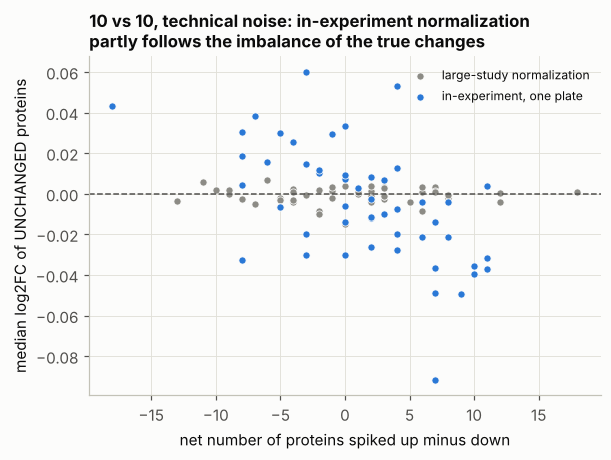

In [13]:
# 3) Why? Hypothesis A: strongly decreased peptides drop below detection, so the values left are biased upward.
#    Test: fit the curves only on precursors seen in every run (dashed line above). If dropout drove the error,
#    this should fix it.
# Hypothesis B: each experiment's spiked changes are randomly unbalanced (e.g. more proteins up than down), and
#    the median-based curve partly follows that imbalance, shifting ALL proteins in one group a little.
#    Test: the shift of unchanged proteins should track the net number of up- minus down-changed proteins.
u = s20[s20["p"].notna()].copy()

def per_sim(d):
    return pd.Series({"shift of unchanged (log2)": d.loc[d["truth"] == 0, "log2fc"].median(),
                      "net up - down": np.sign(d["truth"]).sum()})

diag = u.groupby(["scenario", "n_per_group", "noise_sd", "sim"]).apply(per_sim)
from scipy.stats import spearmanr
summary_rows = []
for (scenario, n, noise), d in diag.groupby(level=[0, 1, 2]):
    summary_rows.append({"scenario": scenario, "n_per_group": n, "noise_sd": noise,
                         "SD of shift between experiments": d["shift of unchanged (log2)"].std(),
                         "rho(shift, net up - down)": spearmanr(d["shift of unchanged (log2)"], d["net up - down"])[0]})
display(pd.DataFrame(summary_rows).set_index(["scenario", "n_per_group", "noise_sd"]).unstack("noise_sd").round(3))

fig, ax = plt.subplots(figsize=(6, 4))
for scenario in ["large-study normalization", "in-experiment, one plate"]:
    d = diag.loc[(scenario, 10, 0.0)]
    ax.scatter(d["net up - down"], d["shift of unchanged (log2)"], s=22, color=STRESS_COLORS[scenario],
               edgecolor=plotting.SURFACE, linewidth=0.5, label=scenario)
ax.axhline(0, color=INK_MUTED, lw=1, ls="--")
ax.set_xlabel("net number of proteins spiked up minus down")
ax.set_ylabel("median log2FC of UNCHANGED proteins")
ax.set_title("10 vs 10, technical noise: in-experiment normalization\npartly follows the imbalance of the true changes")
ax.legend(fontsize=8)
plotting.save_figure(fig, "03_stress_imbalance", FIGURES)
plt.show()

In [14]:
# 4) Closer to a selective degrader: only 5% of proteins change (100 simulations per cell; few calls each)
s5 = stress[stress["change"] == "5% changed"]
fdr5 = {"q < 0.05": benchmark.score(s5, by=by, ci=0.95),
        "q < 0.05 and |log2FC| >= 0.58": benchmark.score(s5, by=by, ci=0.95, min_abs_fc=0.58)}
pd.concat(fdr5, names=["rule"])[["calls / sim", "empirical FDR", "FDR low", "FDR high", "power"]].unstack("noise_sd").round(3)

calls / sim  \
noise_sd                                                                   0.00   
rule                          scenario                  n_per_group               
q < 0.05                      in-experiment, one plate  3.0                8.07   
                                                        5.0                7.97   
                                                        10.0               8.92   
                              large-study normalization 3.0                7.74   
                                                        5.0                7.90   
                                                        10.0               8.05   
q < 0.05 and |log2FC| >= 0.58 in-experiment, one plate  3.0                6.30   
                                                        5.0                6.00   
                                                        10.0               6.29   
                              large-study normalization 3.0                5.99   
                                                        5.0                6.39   
                                                        10.0               6.36   

                                                                           \
noise_sd                                                             0.25   
rule                          scenario                  n_per_group         
q < 0.05                      in-experiment, one plate  3.0          4.47   
                                                        5.0          6.17   
                                                        10.0         7.50   
                              large-study normalization 3.0          4.08   
                                                        5.0          6.20   
                                                        10.0         7.42   
q < 0.05 and |log2FC| >= 0.58 in-experiment, one plate  3.0          4.45   
                                                        5.0          5.69   
                                                        10.0         6.26   
                              large-study normalization 3.0          4.04   
                                                        5.0          5.64   
                                                        10.0         6.29   

                                                                    empirical FDR  \
noise_sd                                                                     0.00   
rule                          scenario                  n_per_group                 
q < 0.05                      in-experiment, one plate  3.0                 0.086   
                                                        5.0                 0.070   
                                                        10.0                0.136   
                              large-study normalization 3.0                 0.062   
                                                        5.0                 0.039   
                                                        10.0                0.031   
q < 0.05 and |log2FC| >= 0.58 in-experiment, one plate  3.0                 0.010   
                                                        5.0                 0.000   
                                                        10.0                0.000   
                              large-study normalization 3.0                 0.008   
                                                        5.0                 0.002   
                                                        10.0                0.000   

                                                                            \
noise_sd                                                              0.25   
rule                          scenario                  n_per_group          
q < 0.05                      in-experiment, one plate  3.0          0.092   
                                                        5.0          0.049   


**Interpretation**

* **With nothing changed, p-values stay honest.** Normalizing each experiment on its own runs gives 4.1–6.4% of null proteins below p = 0.05 (large-study normalization: 4.6–5.5%). Small-study normalization adds noise, but the moderated t's variance estimates absorb it.
* **With 20% of proteins changed, FDR is no longer controlled when the data are precise.**
  * **Technical noise only:** 8–14% FDR at 3 or 5 per group, rising to **34% (one plate) and 42% (any plate) at 10 per group**.
  * **CV ~18%:** 4–10%, also highest at n = 10.
  * Power barely changes (at most about 6 points lower). The extra calls are false ones.
* **Why: hypothesis A (dropout) is rejected; hypothesis B (imbalance) is supported.**
  * Fitting the curves only on precursors seen in every run hardly helps (30% instead of 34% at n = 10; dashed line). Missing values are not the main cause.
  * Instead, unchanged proteins move together by a small, experiment-specific amount: between-experiment SD 0.024–0.039 log2, versus 0.004–0.007 with large-study normalization.
  * That offset follows the imbalance of the true changes (Spearman ρ −0.22 to −0.61 against "net proteins up minus down"; about 0 for large-study normalization).
  * **Mechanism:** the normalization defines "typical" as the bulk of the run. If more of the changed proteins happen to go up than down, the bulk moves up a little, and the correction pulls *every* protein in that group down a little. A 0.03 log2 offset is invisible at CV 18% with 3 replicates, but highly "significant" with 10 replicates at 4% CV. **More replicates make it worse, not better**, because the offset is systematic, not random.
  * Drawing runs from one plate or from anywhere makes little difference, so plate and drift effects are not the issue either.
* **This is not specific to small studies.** Any real study's normalization sees its own changes; the large-study scenario looks clean only because the changes were added *after* normalization.
* **An effect-size filter neutralizes it.** With q < 0.05 **and** |log2FC| ≥ 0.58, FDR is ≤ 4.2% in every in-experiment scenario at 20% change. The price is power, almost all of it among the 1.5-fold changes, which sit right at the cutoff: at CV ~18% it costs 1 point at n = 3 but up to 13 points at n = 10 (0.80 instead of 0.93); with technical noise only, power is about 0.8 instead of 0.99.
* **With only 5% of proteins changed (closer to a selective degrader), the problem is milder:** FDR 5–9% at n = 3–5 and 14% [8–20%] at n = 10 with technical noise. With the filter: ≤ 3.2% in every cell except 3 vs 3 at CV ~18%. There, FDR is 9% [7–12%] with or without the filter (large-study normalization: 6–7%), because estimated fold changes are themselves too noisy for a cutoff to separate.

**Decision.**
* **The fold-change filter moves from "optional" to "recommended":** `stats.differential(..., min_abs_fc=0.58)` and `RECOMMENDED["min_abs_fc"]`.
* **The calibration in sections 3–4 should be read as a best case.** In a small study with biological variability, a list at q < 0.05 realistically carries **5–10% false discoveries**, which is one more reason to confirm key hits with an orthogonal method (e.g. targeted PRM or a western blot).

## 5. Shortcuts: fold-change cutoffs and unadjusted p-values

Two shortcuts are common in practice:
* calling hits by fold change alone ("|log2FC| ≥ 1")
* calling hits by unadjusted p < 0.05

Here they are scored on the same simulations, alongside q < 0.05 with and without an effect-size filter, all using the chosen test.

empirical FDR                power  \
noise_sd                                           0.00   0.25   0.50   0.00   
rule                          n_per_group                                      
|log2FC| >= 1 only            3.0                 0.000  0.055  0.327  0.487   
                              5.0                 0.001  0.013  0.176  0.490   
                              10.0                0.000  0.005  0.078  0.496   
p < 0.05 (unadjusted)         3.0                 0.155  0.211  0.258  0.995   
                              5.0                 0.166  0.187  0.220  0.996   
                              10.0                0.165  0.173  0.192  0.999   
q < 0.05                      3.0                 0.048  0.053  0.060  0.986   
                              5.0                 0.035  0.047  0.037  0.990   
                              10.0                0.050  0.040  0.043  0.999   
q < 0.05 and |log2FC| >= 0.58 3.0                 0.002  0.050  0.060  0.810   
                              5.0                 0.002  0.023  0.037  0.836   
                              10.0                0.000  0.009  0.030  0.837   

                                                         
noise_sd                                    0.25   0.50  
rule                          n_per_group                
|log2FC| >= 1 only            3.0          0.497  0.535  
                              5.0          0.507  0.529  
                              10.0         0.488  0.534  
p < 0.05 (unadjusted)         3.0          0.853  0.614  
                              5.0          0.910  0.720  
                              10.0         0.980  0.858  
q < 0.05                      3.0          0.699  0.255  
                              5.0          0.835  0.498  
                              10.0         0.945  0.724  
q < 0.05 and |log2FC| >= 0.58 3.0          0.680  0.255  
                              5.0          0.756  0.497  
                              10.0         0.806  0.689

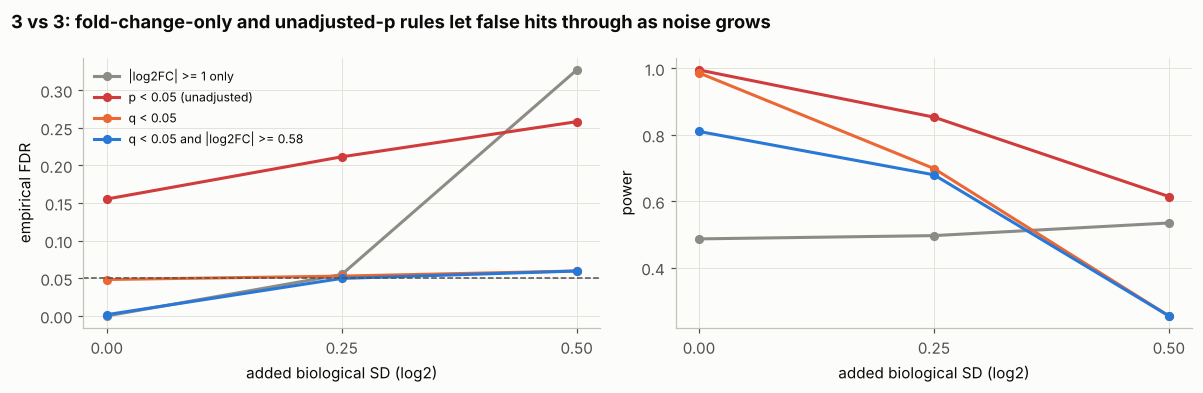

In [15]:
r = spike[spike["p"].notna() & (spike["test"] == "moderated (trend)")].copy()
rules = {
    "|log2FC| >= 1 only": lambda d: d["log2fc"].abs() >= 1,
    "p < 0.05 (unadjusted)": lambda d: d["p"] < 0.05,
    "q < 0.05": lambda d: d["q"] < 0.05,
    "q < 0.05 and |log2FC| >= 0.58": lambda d: (d["q"] < 0.05) & (d["log2fc"].abs() >= 0.58),
}

def rule_score(d, called):
    # A call is true only if the protein truly changed AND the direction is right
    true_call = called & (d["truth"] != 0) & (np.sign(d["log2fc"]) == np.sign(d["truth"]))
    return pd.Series({"empirical FDR": (called & ~true_call).sum() / max(called.sum(), 1),
                      "power": true_call.sum() / (d["truth"] != 0).sum()})

rule_table = pd.concat({name: r.groupby(["n_per_group", "noise_sd"]).apply(lambda d: rule_score(d, fn(d)))
                        for name, fn in rules.items()}, names=["rule"])
display(rule_table.unstack("noise_sd").round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
three = rule_table.xs(3, level="n_per_group")
rule_colors = dict(zip(rules, ["#8c8b85", "#d03b3b", "#eb6834", "#2a78d6"]))
for name in rules:
    t = three.xs(name, level="rule")
    axes[0].plot(t.index, t["empirical FDR"], "-o", color=rule_colors[name], label=name)
    axes[1].plot(t.index, t["power"], "-o", color=rule_colors[name])
axes[0].axhline(0.05, color=INK_MUTED, lw=1, ls="--")
axes[0].set_ylabel("empirical FDR")
axes[1].set_ylabel("power")
for ax in axes:
    ax.set_xlabel("added biological SD (log2)")
    ax.set_xticks(grid["noise_sd"])
axes[0].legend(fontsize=8, loc="upper left")
fig.suptitle("3 vs 3: fold-change-only and unadjusted-p rules let false hits through as noise grows",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plotting.save_figure(fig, "03_decision_rules", FIGURES)
plt.show()

**Interpretation**
* **Fold change alone looks fine on clean data and fails on noisy data:** at 3 vs 3 its FDR rises from 0% to about 33% at CV 35%. It also cannot find changes smaller than its own cutoff (power capped around 50%, because the 1.5-fold changes are invisible to it).
* **Unadjusted p < 0.05 has an FDR of 16–26% in every scenario.** With about 150 proteins tested, 5% of the unchanged ones pass by chance every time. Multiple-testing correction is not optional.
* **q < 0.05 holds FDR near 5% everywhere.**
* **Adding |log2FC| ≥ 0.58 on top** lowers FDR further when noise is low, at a modest cost in power. That is useful when only biologically meaningful changes matter, or when n is large (§9 shows why).

## 6. Missing values: impute or not, and how to handle "on/off" proteins

Notebook 02 deferred imputation to here, where it can be graded.

**Setup:**
* 3 vs 3, CV about 18%.
* The fold-change set includes **−4 (16-fold down)**, so that some proteins drop out of one group entirely. This is the on/off pattern a degrader screen produces.

**Strategies compared** (`src/impute.py`):

| Strategy | Assumes values are missing because… |
|---|---|
| none (test only proteins with ≥ 2 values per group) | — |
| down-shifted normal (Perseus-style) | they were below the detection limit |
| run minimum | they were at the detection limit |
| KNN | at random (similar proteins predict them) |

In [16]:
imp_file = PROCESSED / "03_sim_imputation.parquet"
if RERUN or not imp_file.exists():
    imp = benchmark.run_grid(precursors, protein_of, pool, n_sims=50, seed=3, tests=("moderated (trend)",),
                             imputations=tuple(impute.STRATEGIES), fold_changes=(-4, -2, -1, -0.58, 0.58, 1, 2),
                             n_per_group=[3], noise_sd=[0.25])
    imp.to_parquet(imp_file)
imp = pd.read_parquet(imp_file)

display(benchmark.score(imp, by=("imputation",)).round(3))

# How often does a protein look "on/off" (absent from one group), and is it really changed?
base = imp[imp["imputation"] == "none"]
onoff = base[base["status_original"].str.startswith("absent")].copy()
onoff["implied direction"] = np.where(onoff["status_original"] == "absent in b", -1, 1)
onoff["really changed that way"] = np.sign(onoff["truth"]) == onoff["implied direction"]
strict = ((onoff["n_a"] == 0) & (onoff["n_b"] == 3)) | ((onoff["n_b"] == 0) & (onoff["n_a"] == 3))
print(f"On/off proteins per experiment: {len(onoff) / 50:.1f}")
print(f"  'absent from one group' (< 2 values): truly changed in that direction {onoff['really changed that way'].mean():.0%}")
print(f"  strict (0 values vs all 3):          truly changed in that direction {onoff.loc[strict, 'really changed that way'].mean():.0%}")

# Imputation then testing: how many on/off proteins get called, and how many of those calls are false?
rows = []
for name in ["down-shifted normal", "run minimum", "KNN"]:
    d = imp[(imp["imputation"] == name) & imp["status_original"].str.startswith("absent") & (imp["q"] < 0.05)]
    ok = (d["truth"] != 0) & (np.sign(d["log2fc"]) == np.sign(d["truth"]))
    rows.append({"imputation": name, "on/off calls per experiment": len(d) / 50, "false among them": 1 - ok.mean()})
pd.DataFrame(rows).set_index("imputation").round(2)

,calls / sim,empirical FDR,power
imputation,,,
KNN,21.02,0.065,0.633
down-shifted normal,21.30,0.038,0.660
none,20.84,0.050,0.709
run minimum,22.00,0.042,0.679


On/off proteins per experiment: 5.9
  'absent from one group' (< 2 values): truly changed in that direction 48%
  strict (0 values vs all 3):          truly changed in that direction 91%


,on/off calls per experiment,false among them
imputation,,
down-shifted normal,1.84,0.05
run minimum,2.36,0.08
KNN,0.70,0.54


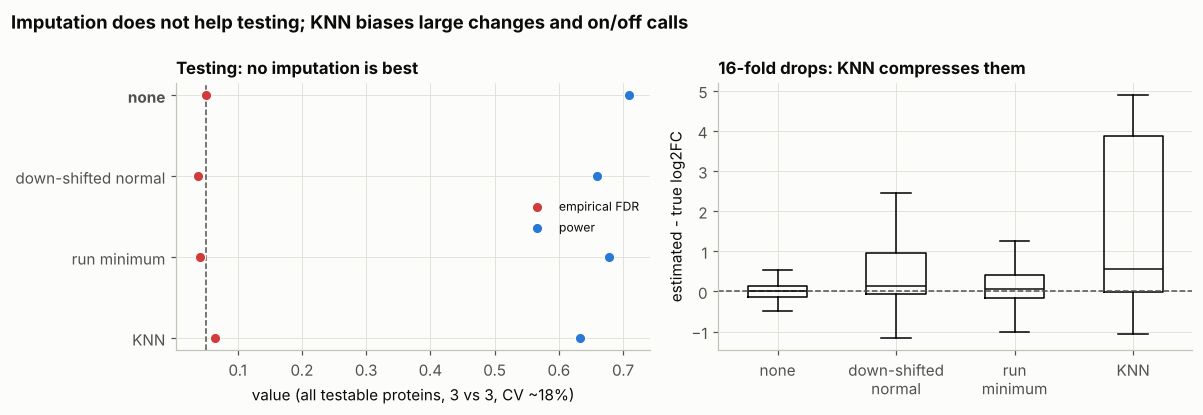

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
s = benchmark.score(imp, by=("imputation",))
order = ["none", "down-shifted normal", "run minimum", "KNN"]
colors = {"empirical FDR": "#d03b3b", "power": "#2a78d6"}
plotting.dot_scoreboard(axes[0], s.loc[order], ["empirical FDR", "power"], colors,
                        xlabel="value (all testable proteins, 3 vs 3, CV ~18%)", highlight="none")
axes[0].axvline(0.05, color=INK_MUTED, lw=1, ls="--")
axes[0].legend(loc="center right", fontsize=8)
axes[0].set_title("Testing: no imputation is best")

err = imp[imp["p"].notna() & (imp["truth"] == -4)].copy()
err["error"] = err["log2fc"] - err["truth"]
pos = np.arange(len(order))
axes[1].boxplot([err.loc[err["imputation"] == k, "error"] for k in order], positions=pos, widths=0.5,
                showfliers=False, medianprops={"color": "#0b0b0b"})
axes[1].axhline(0, color=INK_MUTED, lw=1, ls="--")
axes[1].set_xticks(pos, [o.replace(" ", "\n", 1) for o in order])
axes[1].set_ylabel("estimated - true log2FC")
axes[1].set_title("16-fold drops: KNN compresses them")
fig.suptitle("Imputation does not help testing; KNN biases large changes and on/off calls",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plotting.save_figure(fig, "03_imputation", FIGURES)
plt.show()

**Interpretation**
* **For proteins quantified in both groups, imputation never helps.**
  * No imputation has the highest power (0.71) at FDR 5.0%.
  * Down-shifted normal and run-minimum imputation slightly reduce power, by distorting variances.
  * **KNN raises FDR to about 6.5% and compresses large drops:** a true 16-fold decrease is reported as roughly 11-fold (median). KNN assumes values are missing at random, but here they are missing *because* they are low.
  * **Reading the right-hand panel fairly:** "none" can only estimate the 16-fold drops still detected in both groups. The imputed versions also estimate the drops that became on/off, which are inherently harder. Down-shifted imputation is roughly centred but imprecise for them. That is acceptable for *calling* an on/off protein, but its fold change should not be over-interpreted.
* **"On/off" proteins need their own rule, and the obvious one is wrong.**
  * About 6 proteins per 3 vs 3 experiment look absent from one group, but **only about half are truly changed in that direction**. At n = 3, low-abundance proteins drop out of a group by chance.
  * The strict pattern (0 values in one group, all 3 in the other) is right about 90% of the time.
  * **Down-shifted imputation followed by the moderated test** calls a similar number, with about **5% false**.
  * KNN gets more than half of its on/off calls wrong.
* **Decision (implemented in `stats.differential`):**
  * test proteins with ≥ 2 values per group **without imputation**
  * test on/off proteins **separately**, after down-shifted-normal imputation, with their own q-values, so the two tiers never dilute each other
  * report the tier with every call

## 7. Are fold changes estimated without bias?

In [18]:
acc = spike[spike["p"].notna() & (spike["test"] == "moderated (trend)")].copy()
acc["error"] = acc["log2fc"] - acc["truth"]
summary = acc.groupby(["noise_sd", "truth"])["error"].agg(["median", "std"]).unstack("noise_sd").round(3)
summary.columns = [f"{stat} error, noise {noise}" for stat, noise in summary.columns]
summary

,"median error, noise 0.0","median error, noise 0.25","median error, noise 0.5","std error, noise 0.0","std error, noise 0.25","std error, noise 0.5"
truth,,,,,,
-2.00,0.008,0.012,0.025,0.055,0.236,0.423
-1.00,0.002,0.006,-0.009,0.048,0.200,0.430
-0.58,0.001,0.008,0.002,0.064,0.230,0.433
0.00,-0.000,0.000,0.002,0.063,0.219,0.422
0.58,0.001,-0.001,0.007,0.070,0.209,0.447
1.00,-0.000,0.001,-0.001,0.068,0.217,0.416
2.00,0.001,-0.001,-0.019,0.065,0.206,0.431


**Interpretation**
* **Median errors are within about ±0.03 log2 for every true fold change:** no systematic compression or inflation, including for decreases, where some precursors drop below detection.
* **The spread of errors grows with noise**, as it must, which is why replicates are needed.
* **The blind spot:** in a *real* mixed proteome, interfering peptides from other proteins compress measured ratios towards 1. A spike-in into one material cannot reproduce that. Checking compression needs a genuine hybrid-proteome benchmark, which is planned as a short validation notebook once a full pre-searched report is available.

## 8. Recommended settings, and how many replicates to plan for

fold change           1.5-fold  2.0-fold  4.0-fold
noise_sd n_per_group                              
0.00     3.0              0.97      1.00      1.00
         5.0              0.97      1.00      1.00
         10.0             1.00      1.00      1.00
0.25     3.0              0.34      0.80      0.98
         5.0              0.62      0.91      1.00
         10.0             0.86      0.97      1.00
0.50     3.0              0.02      0.12      0.65
         5.0              0.14      0.49      0.86
         10.0             0.44      0.75      0.95

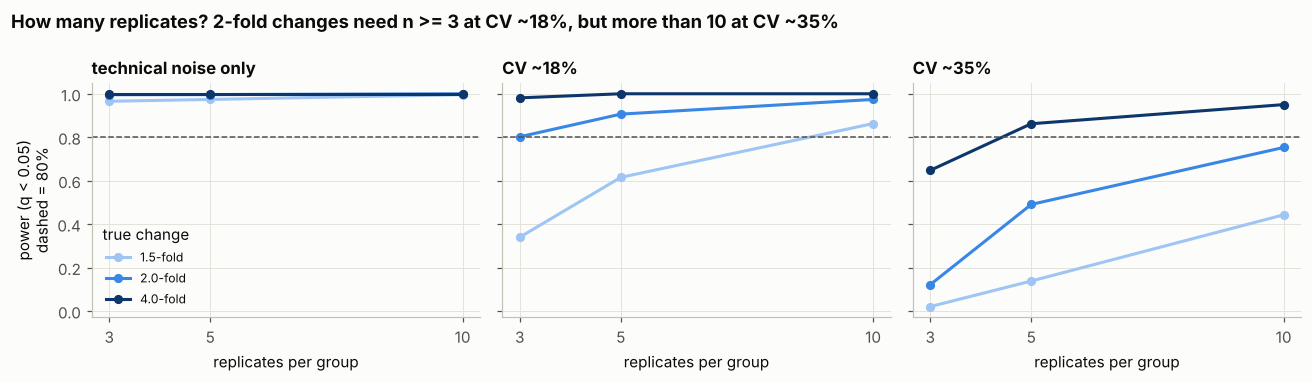

Recommended settings (src/stats.py, RECOMMENDED): {'test': 'moderated (trend)', 'alpha': 0.05, 'min_per_group': 2, 'on_off_imputation': 'down-shifted normal', 'min_abs_fc': 0.58}


In [19]:
# Power by true effect size, replicates and noise, for the recommended test
rec = spike[spike["p"].notna() & (spike["test"] == "moderated (trend)") & (spike["truth"] != 0)].copy()
rec["found"] = (rec["q"] < 0.05) & (np.sign(rec["log2fc"]) == np.sign(rec["truth"]))
rec["fold change"] = (2 ** rec["truth"].abs()).round(1).astype(str) + "-fold"
power_table = rec.groupby(["noise_sd", "n_per_group", "fold change"])["found"].mean().unstack("fold change")
display(power_table.round(2))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
fc_colors = {"1.5-fold": "#9ec5f4", "2.0-fold": "#3987e5", "4.0-fold": "#0d366b"}
for ax, noise in zip(axes, grid["noise_sd"]):
    t = power_table.xs(noise, level="noise_sd")
    for fc, color in fc_colors.items():
        ax.plot(t.index, t[fc], "-o", color=color, label=fc)
    ax.axhline(0.8, color=INK_MUTED, lw=1, ls="--")
    ax.set_xticks(grid["n_per_group"])
    ax.set_xlabel("replicates per group")
    ax.set_title({0.0: "technical noise only", 0.25: "CV ~18%", 0.5: "CV ~35%"}[noise])
axes[0].set_ylabel("power (q < 0.05)\ndashed = 80%")
axes[0].legend(title="true change", fontsize=8)
fig.suptitle("How many replicates? 2-fold changes need n >= 3 at CV ~18%, but more than 10 at CV ~35%",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plotting.save_figure(fig, "03_power_by_effect", FIGURES)
plt.show()
print("Recommended settings (src/stats.py, RECOMMENDED):", stats.RECOMMENDED)

**Recommended analysis** (`stats.differential`), carried forward to every later notebook:

| Step | Setting | Evidence |
|---|---|---|
| Test | Moderated t, intensity-dependent prior | Honest p-values (§3); FDR about 5% with the highest power (§4); matches the measured mean–variance trend (§2) |
| Cutoff | BH q < 0.05 **plus \|log2FC\| ≥ 0.58** | Unadjusted p gives 16–26% FDR; fold change alone up to 33% (§5); without the effect-size filter, normalization offsets inflate FDR to 34–42% in precise data (§4b) |
| Missing values | No imputation for testing; on/off proteins as a separate tier (down-shifted imputation, own q-values) | Best power; about 5% false on/off calls, vs about 50% for "absent from one group" (§6) |

**Study design guidance**, from the power table:
* **With replicate CVs around 18%** (typical cell culture), **3 replicates per group find about 80% of 2-fold changes but only about a third of 1.5-fold changes.** Detecting 1.5-fold changes reliably needs about 10.
* **At CVs around 35%**, even 2-fold changes need more than 10 replicates per group (75% power at n = 10).
* **For a degrader screen:** the first-pass question (strong, near-complete degradation of a few proteins) is well served by 3 replicates. Subtle downstream effects are not.

## 9. Real data, and how to reuse this for a new dataset

The recommended analysis is applied to plasma vs serum (log2FC = serum − plasma), first with all wells, then with a realistic 3 vs 3 subsample.

**What changes for another dataset, e.g. a degrader screen:** only the **design table** (run → group) and the two group names.

,all wells (91 vs 75),3 vs 3,"3 vs 3, |log2FC| >= 0.58"
call,,,
down,78,64,26
not significant,7,29,110
not testable,0,3,3
up,73,62,19


,n_a,n_b,log2fc,q,tier,call
ALB,3,3,0.115,0.006,tested,up
APOA1,3,3,0.147,0.001,tested,up
FGB,3,0,-8.626,0.000,on/off,down
FGG,3,0,-8.390,0.000,on/off,down
FGA,3,3,-5.853,0.000,tested,down


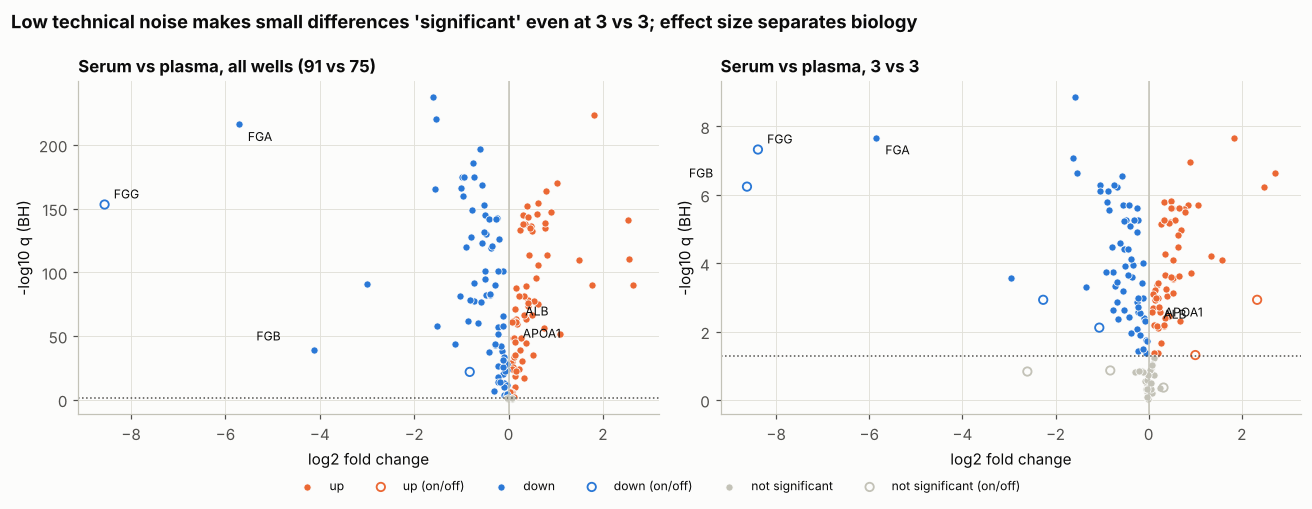

In [20]:
proteins = pd.read_parquet(PROCESSED / "02_proteins_maxlfq.parquet")
labels = {pg: gene_of.get(pg, pg) for pg in gene_of.index[gene_of.isin(["FGA", "FGB", "FGG", "ALB", "APOA1"])]}

# 1) The design table: the ONLY dataset-specific input
design_all = meta.loc[meta["sample_type"].isin(["Plasma", "Serum"]), "sample_type"]

# 2) A realistic small study: 3 random wells per group
rng = np.random.default_rng(7)
design_3v3 = pd.concat([design_all[design_all == g].sample(3, random_state=rng) for g in ["Plasma", "Serum"]])

results = {"all wells (91 vs 75)": stats.differential(proteins, design_all, "Plasma", "Serum"),
           "3 vs 3": stats.differential(proteins, design_3v3, "Plasma", "Serum"),
           "3 vs 3, |log2FC| >= 0.58": stats.differential(proteins, design_3v3, "Plasma", "Serum", min_abs_fc=0.58)}
summary = pd.DataFrame({k: v["call"].value_counts() for k, v in results.items()}).fillna(0).astype(int)
display(summary)
display(results["3 vs 3"].loc[list(labels), ["n_a", "n_b", "log2fc", "q", "tier", "call"]]
        .rename(index=labels).round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, key in zip(axes, ["all wells (91 vs 75)", "3 vs 3"]):
    plotting.volcano(ax, results[key], label=labels, title=f"Serum vs plasma, {key}")
handles, names = axes[1].get_legend_handles_labels()
fig.legend(handles, names, loc="lower center", ncol=6, fontsize=8, bbox_to_anchor=(0.5, -0.04))
fig.suptitle("Low technical noise makes small differences 'significant' even at 3 vs 3; effect size separates biology",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plotting.save_figure(fig, "03_volcano_plasma_serum", FIGURES)
plt.show()

**Interpretation**
* **With 91 vs 75 wells and CVs of about 4%, nearly every protein is "significant"**, including albumin at +0.16 log2 (1.1-fold). That difference is probably real (serum and plasma do differ slightly, and normalization is never perfect), but it is biologically trivial. **With large n, statistical significance stops being informative; effect size is what matters.**
* **Even at 3 vs 3, 126 of 158 proteins are called.** These wells are technical replicates with CVs of about 4%, far cleaner than any biological study (§4 simulated CV 18–35% for that reason), so tiny but consistent matrix differences reach significance even with 3 per group.
  * **Fibrinogen remains the dominant change:** FGA about −5.9 log2.
  * **FGB and FGG appear as on/off proteins** (hollow markers; absent in all 3 serum wells), handled by the separate tier rather than ignored or naively imputed.
* **Adding |log2FC| ≥ 0.58 cuts the list from 126 to 45.** When noise is this low, or n this large, the effect-size filter is what turns "detectable" into "worth following up".

### Template: applying this to a new dataset (e.g. a degrader screen)
```python
# design: one row per run, the group it belongs to
design = pd.Series({"run_01": "DMSO", "run_02": "DMSO", "run_03": "DMSO",
                    "run_04": "cmpd_1uM", "run_05": "cmpd_1uM", "run_06": "cmpd_1uM"})
result = stats.differential(protein_matrix, design, "DMSO", "cmpd_1uM", min_abs_fc=0.58)
hits = result[result["call"] != "not significant"]       # includes on/off degradation candidates
plotting.volcano(ax, result)
```
**Before running it on a new dataset, re-check Notebook 02's normalization assumptions** (most proteins unchanged in each run; randomized run order). A strong degrader changes few proteins, which suits RT-dependent normalization. Treatment blocks run in sequence would rule out the sample-anchored drift step.

## 10. Summary

In [21]:
# Save the recommended settings next to the data outputs, so later notebooks can read them
import json
(PROCESSED / "03_recommended_settings.json").write_text(json.dumps(stats.RECOMMENDED, indent=2))
print("Saved:", [p.name for p in sorted(PROCESSED.glob("03_*"))])

Saved: ['03_recommended_settings.json', '03_sim_imputation.parquet', '03_sim_null.parquet', '03_sim_smalln.parquet', '03_sim_spike.parquet']


| Question | Finding | Decision |
|---|---|---|
| Do the implementations work? | Moderated t recovers a known prior; null p-values uniform; trend version fixes intensity-dependent noise | Validated before use |
| Is noise intensity-dependent here? | Yes: SD about 4× higher for the least abundant proteins (ρ ≈ −0.69) | Use the intensity-trend prior |
| Honest p-values? | Moderated tests: 4.4–5.5% of nulls below 0.05. Welch conservative at small n | — |
| Which test? | All control FDR near 5%; at 3 vs 3 moderated tests find 70% of true changes vs 28% for Welch (CV ~18%) | **Moderated t (trend)** |
| Does it survive a small study's own normalization? | Null still honest; but with many changed proteins, normalization shifts all proteins by ~0.03 log2, and FDR reaches 34–42% in precise data. Not caused by dropout (tested) | Read §3–4 as a best case: realistic FDR 5–10% |
| Shortcuts? | Fold change alone: FDR up to 33%; unadjusted p: 16–26% | **BH q < 0.05 plus \|log2FC\| ≥ 0.58** (≤ 4.2% FDR in the §4b stress test) |
| Imputation? | No benefit for testing; KNN biased. "Absent from one group" is a true change only about half the time | **No imputation; on/off tier with down-shifted imputation** (about 5% false) |
| Fold-change bias? | None detectable (±0.03 log2) | Ratio compression in real mixtures still to be checked on a hybrid benchmark |
| Replicates? | n = 3 finds about 80% of 2-fold changes at CV ~18%, about a third of 1.5-fold changes | Design guidance for the degrader dataset |

**Limitations**
* **Semi-synthetic truth.** Spiked changes are clean shifts; real mixtures add interference (ratio compression), and real biology adds correlated changes between proteins. Both would need a genuine benchmark or biological dataset to assess.
* **The added biological noise is simulated** (log-normal spread of protein SDs, no intensity trend). Its levels were chosen to span typical replicate CVs, not measured.
* **The stress test (§4b) uses RT-dependent normalization only.** Other normalizations (e.g. on a set of proteins assumed unchanged) would behave differently; any normalization anchored on "the bulk" shares the imbalance problem.
* **The plasma wells are not perfectly identical.** A few donor-variable proteins (immunoglobulins, LPA, ORM1, FN1) vary 5–14× more between wells than in the repeatedly injected pooled QC, against about 3× for typical proteins. That is consistent with the two plasma lots listed on PRIDE, or with protein-specific preparation effects. Random splits keep the tests valid, but false calls among these co-varying proteins come in bursts, which is why FDRs carry bootstrap intervals in §4b.
* **The protein universe is small** (about 150 plasma proteins at 5-minute gradients). Deeper datasets have more low-abundance proteins, where the intensity trend and the on/off rules matter even more.